BCMID_Multimodal_Medical_AI
│
├── 01. Environment & Imports
├── 02. Dataset Exploration
├── 03. Load BI-RADS Annotations
├── 04. Patient Structure Analysis
├── 05. Build Multimodal Manifest
├── 06. Image Integrity Check
├── 07. Missing Modality Analysis
├── 08. Duplicate Detection
├── 09. Image Quality Analysis
├── 10. Data Validation
├── 11. Image Preprocessing
├── 12. Patient-Level Dataset Split
├── 13. Quality Report
└── 14. Save Validated Dataset

In [1]:
# ============================================================
# 01. ENVIRONMENT & IMPORTS
# BCMID Multimodal Medical AI
# ============================================================

# -----------------------------
# 1. Standard libraries
# -----------------------------
import os
import json
import random
import hashlib
import warnings
from pathlib import Path
from collections import Counter

# -----------------------------
# 2. Data processing
# -----------------------------
import numpy as np
import pandas as pd

# -----------------------------
# 3. Medical image handling
# -----------------------------
from PIL import Image, ImageFile

# Allow PIL to open some truncated images
ImageFile.LOAD_TRUNCATED_IMAGES = True

# -----------------------------
# 4. Machine Learning
# -----------------------------
from sklearn.model_selection import train_test_split

# -----------------------------
# 5. Deep Learning
# -----------------------------
import torch
import torchvision
import torchvision.transforms as transforms

# -----------------------------
# 6. Visualization
# -----------------------------
import matplotlib.pyplot as plt

# -----------------------------
# 7. Warnings
# -----------------------------
warnings.filterwarnings("ignore")

# ============================================================
# REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ============================================================
# DEVICE
# ============================================================

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# ============================================================
# KAGGLE PATHS
# ============================================================

KAGGLE_INPUT = Path("/kaggle/input")
KAGGLE_WORKING = Path("/kaggle/working")

KAGGLE_WORKING.mkdir(
    parents=True,
    exist_ok=True
)

# ============================================================
# IMAGE CONFIGURATION
# ============================================================

IMAGE_EXTENSIONS = {
    ".png",
    ".jpg",
    ".jpeg",
    ".bmp",
    ".tif",
    ".tiff"
}

# ============================================================
# GLOBAL CONFIGURATION
# ============================================================

CONFIG = {
    "seed": SEED,
    "image_size": 224,
    "device": str(DEVICE),
    "dataset_name": "BCMID",
    "dataset_version": "v3"
}

# ============================================================
# DISPLAY ENVIRONMENT INFORMATION
# ============================================================

print("=" * 70)
print("BCMID MULTIMODAL MEDICAL AI")
print("Environment Initialization")
print("=" * 70)

print(f"\nPython environment ready")
print(f"PyTorch version     : {torch.__version__}")
print(f"Torchvision version : {torchvision.__version__}")
print(f"Device              : {DEVICE}")

if torch.cuda.is_available():
    print(f"GPU                 : {torch.cuda.get_device_name(0)}")
else:
    print("GPU                 : Not available")

print(f"\nKaggle input        : {KAGGLE_INPUT}")
print(f"Kaggle working      : {KAGGLE_WORKING}")
print(f"Image size          : {CONFIG['image_size']} x {CONFIG['image_size']}")
print(f"Random seed         : {SEED}")

print("\nEnvironment successfully initialized.")

BCMID MULTIMODAL MEDICAL AI
Environment Initialization

Python environment ready
PyTorch version     : 2.11.0+cu128
Torchvision version : 0.26.0+cu128
Device              : cuda
GPU                 : Tesla T4

Kaggle input        : /kaggle/input
Kaggle working      : /kaggle/working
Image size          : 224 x 224
Random seed         : 42

Environment successfully initialized.


In [2]:
# ============================================================
# 02. DATASET EXPLORATION
# BCMID Multimodal Medical AI
# ============================================================

print("=" * 70)
print("02. DATASET EXPLORATION")
print("=" * 70)

# ============================================================
# 1. Search for the annotation file
# ============================================================

annotation_candidates = list(
    KAGGLE_INPUT.rglob("BCMID_annotations.tsv")
)

if not annotation_candidates:
    raise FileNotFoundError(
        "BCMID_annotations.tsv was not found inside /kaggle/input."
    )

ANNOTATION_PATH = annotation_candidates[0]

print("\nAnnotation file:")
print(ANNOTATION_PATH)

# ============================================================
# 2. Determine dataset root
# ============================================================

DATA_ROOT = ANNOTATION_PATH.parent

print("\nDataset root:")
print(DATA_ROOT)

# ============================================================
# 3. Display directory structure
# ============================================================

print("\nTop-level dataset content:")

for item in sorted(DATA_ROOT.iterdir()):
    if item.is_dir():
        print(f"📁 {item.name}")
    else:
        print(f"📄 {item.name}")

# ============================================================
# 4. Search patient-like directories
# ============================================================

patient_directories = []

for directory in DATA_ROOT.iterdir():

    if not directory.is_dir():
        continue

    children = {
        child.name.lower()
        for child in directory.iterdir()
        if child.is_dir()
    }

    if "mammogram" in children or "ultrasound" in children:
        patient_directories.append(directory)

# ============================================================
# 5. Dataset statistics
# ============================================================

print("\n" + "-" * 70)
print("DATASET STRUCTURE")
print("-" * 70)

print(
    f"Patient directories detected : {len(patient_directories)}"
)

print(
    f"Annotation file exists        : {ANNOTATION_PATH.exists()}"
)

# ============================================================
# 6. Display first patients
# ============================================================

print("\nFirst patient directories:")

for patient in patient_directories[:15]:
    print(f"  └── {patient.name}")

# ============================================================
# 7. Search all image files
# ============================================================

all_image_files = [
    p
    for p in DATA_ROOT.rglob("*")
    if (
        p.is_file()
        and p.suffix.lower() in IMAGE_EXTENSIONS
    )
]

print("\nTotal image files detected:")
print(len(all_image_files))

# ============================================================
# 8. Image extension distribution
# ============================================================

extension_distribution = Counter(
    p.suffix.lower()
    for p in all_image_files
)

print("\nImage format distribution:")

for extension, count in extension_distribution.items():
    print(f"  {extension:8s} : {count}")

print("\nDataset exploration completed.")

02. DATASET EXPLORATION

Annotation file:
/kaggle/input/datasets/samouniomrani/bcmid-multimodal-breast-cancer-dataset/BCMID_annotations.tsv

Dataset root:
/kaggle/input/datasets/samouniomrani/bcmid-multimodal-breast-cancer-dataset

Top-level dataset content:
📁 BCMID
📄 BCMID_annotations.tsv

----------------------------------------------------------------------
DATASET STRUCTURE
----------------------------------------------------------------------
Patient directories detected : 0
Annotation file exists        : True

First patient directories:

Total image files detected:
2001

Image format distribution:
  .png     : 2001

Dataset exploration completed.


In [3]:
# ============================================================
# 03. LOAD BI-RADS ANNOTATIONS
# BCMID Multimodal Medical AI
# ============================================================

print("=" * 70)
print("03. BI-RADS ANNOTATIONS")
print("=" * 70)

# ============================================================
# 1. Load TSV
# ============================================================

annotations_raw = pd.read_csv(
    ANNOTATION_PATH,
    sep="\t"
)

print("\nRaw annotation shape:")
print(annotations_raw.shape)

print("\nColumns:")
for column in annotations_raw.columns:
    print(f"  - {column}")

# ============================================================
# 2. Display raw data
# ============================================================

print("\nFirst rows:")
display(annotations_raw.head())

# ============================================================
# 3. Detect candidate columns
# ============================================================

column_mapping = {
    column: str(column).strip().lower()
    for column in annotations_raw.columns
}

patient_candidates = [
    column
    for column, normalized in column_mapping.items()
    if any(
        keyword in normalized
        for keyword in [
            "patient",
            "subject",
            "case",
            "patient_id"
        ]
    )
]

birads_candidates = [
    column
    for column, normalized in column_mapping.items()
    if any(
        keyword in normalized
        for keyword in [
            "birads",
            "bi-rads",
            "bi_rads",
            "label",
            "category"
        ]
    )
]

print("\nPossible patient ID columns:")
print(patient_candidates)

print("\nPossible BI-RADS columns:")
print(birads_candidates)

# ============================================================
# 4. Select columns
# ============================================================

if len(patient_candidates) == 0:
    raise ValueError(
        "No patient ID column could be detected automatically."
    )

if len(birads_candidates) == 0:
    raise ValueError(
        "No BI-RADS column could be detected automatically."
    )

PATIENT_COLUMN = patient_candidates[0]
BIRADS_COLUMN = birads_candidates[0]

print("\nSelected columns:")
print("Patient ID :", PATIENT_COLUMN)
print("BI-RADS     :", BIRADS_COLUMN)

# ============================================================
# 5. Create clean annotation table
# ============================================================

annotations = annotations_raw[
    [PATIENT_COLUMN, BIRADS_COLUMN]
].copy()

annotations.columns = [
    "patient_id",
    "birads"
]

# ============================================================
# 6. Clean values
# ============================================================

annotations["patient_id"] = (
    annotations["patient_id"]
    .astype(str)
    .str.strip()
)

annotations["birads"] = (
    annotations["birads"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# Remove invalid textual missing values
annotations["birads"] = annotations["birads"].replace(
    {
        "NAN": np.nan,
        "NONE": np.nan,
        "": np.nan
    }
)

# ============================================================
# 7. Remove exact duplicates
# ============================================================

annotations = annotations.drop_duplicates()

# ============================================================
# 8. BI-RADS distribution
# ============================================================

print("\nClean annotation table:")
display(annotations.head(10))

print("\nBI-RADS distribution:")
display(
    annotations["birads"]
    .value_counts(dropna=False)
    .to_frame("count")
)

# ============================================================
# 9. Annotation statistics
# ============================================================

print("\nAnnotation statistics:")
print(
    f"Unique patients : {annotations['patient_id'].nunique()}"
)

print(
    f"Missing BI-RADS  : {annotations['birads'].isna().sum()}"
)

print("\nBI-RADS annotation loading completed.")

03. BI-RADS ANNOTATIONS

Raw annotation shape:
(332, 4)

Columns:
  - Patient ID
  - BI-RADS Label
  - Binary Label
  - Pathology Label

First rows:


,Patient ID,BI-RADS Label,Binary Label,Pathology Label
0,2071y19,2,Negative,Benign
1,3597y17,2,Negative,Benign
2,0470y18,3,Negative,Benign
3,0919y18,1,Negative,Normal
4,0877y07,4,Positive,Malignant



Possible patient ID columns:
['Patient ID']

Possible BI-RADS columns:
['BI-RADS Label', 'Binary Label', 'Pathology Label']

Selected columns:
Patient ID : Patient ID
BI-RADS     : BI-RADS Label

Clean annotation table:


,patient_id,birads
0,2071y19,2
1,3597y17,2
2,0470y18,3
3,0919y18,1
4,0877y07,4
5,04138y20,2
6,1780y07,2
7,1238y19,2
8,2889y13,3
9,3679y19,1



BI-RADS distribution:


,count
birads,
2,167
1,50
3,47
4,24
6,24
5,15
0,5



Annotation statistics:
Unique patients : 332
Missing BI-RADS  : 0

BI-RADS annotation loading completed.


In [4]:
# ============================================================
# 04. PATIENT STRUCTURE ANALYSIS
# BCMID Multimodal Medical AI
# ============================================================

print("=" * 70)
print("04. PATIENT STRUCTURE ANALYSIS")
print("=" * 70)

# ============================================================
# 1. VERIFY DATA ROOT
# ============================================================

print("\n[1/5] Dataset root:")
print(DATA_ROOT)

if not DATA_ROOT.exists():
    raise FileNotFoundError(
        f"Dataset root does not exist: {DATA_ROOT}"
    )

# ============================================================
# 2. DISPLAY REAL DATASET STRUCTURE
# ============================================================

print("\n[2/5] Inspecting dataset structure...")

for item in list(DATA_ROOT.iterdir())[:20]:

    if item.is_dir():
        print(f"📁 {item.name}/")

    else:
        print(f"📄 {item.name}")

# ============================================================
# 3. FIND PATIENT DIRECTORIES RECURSIVELY
# ============================================================

print("\n[3/5] Searching for patient directories...")

def find_patient_directories(root):
    """
    Find every directory that directly contains
    a Mammogram and/or Ultrasound folder.
    """

    patients = []

    for directory in root.rglob("*"):

        # Only directories
        if not directory.is_dir():
            continue

        # Names of direct children
        child_directories = {
            child.name.lower()
            for child in directory.iterdir()
            if child.is_dir()
        }

        # A patient directory contains one or both modalities
        if (
            "mammogram" in child_directories
            or
            "ultrasound" in child_directories
        ):
            patients.append(directory)

    return sorted(
        set(patients)
    )


patient_directories = find_patient_directories(
    DATA_ROOT
)

print(
    f"\nPatient directories detected: "
    f"{len(patient_directories)}"
)

# ============================================================
# 4. IF NOTHING FOUND → DIAGNOSTIC SEARCH
# ============================================================

if len(patient_directories) == 0:

    print("\n" + "!" * 70)
    print("WARNING: NO PATIENT DIRECTORY DETECTED")
    print("!" * 70)

    print(
        "\nSearching explicitly for Mammogram folders..."
    )

    mammogram_folders = [
        p
        for p in DATA_ROOT.rglob("*")
        if (
            p.is_dir()
            and p.name.lower() == "mammogram"
        )
    ]

    print(
        f"Mammogram folders found: "
        f"{len(mammogram_folders)}"
    )

    for folder in mammogram_folders[:10]:
        print(
            "  →",
            folder
        )

    print(
        "\nSearching explicitly for Ultrasound folders..."
    )

    ultrasound_folders = [
        p
        for p in DATA_ROOT.rglob("*")
        if (
            p.is_dir()
            and p.name.lower() == "ultrasound"
        )
    ]

    print(
        f"Ultrasound folders found: "
        f"{len(ultrasound_folders)}"
    )

    for folder in ultrasound_folders[:10]:
        print(
            "  →",
            folder
        )

    raise RuntimeError(
        "\nNo patient directories detected. "
        "Check the dataset structure displayed above."
    )

# ============================================================
# 5. IMAGE SEARCH FUNCTION
# ============================================================

print("\n[4/5] Defining image search function...")

def get_image_files(folder):
    """
    Return all supported image files
    inside a modality folder.
    """

    if folder is None:
        return []

    if not folder.exists():
        return []

    return sorted([
        file
        for file in folder.rglob("*")
        if (
            file.is_file()
            and
            file.suffix.lower()
            in IMAGE_EXTENSIONS
        )
    ])

# ============================================================
# 6. ANALYZE EVERY PATIENT
# ============================================================

print("\n[5/5] Analyzing patient structures...")

patient_records = []

for patient_directory in patient_directories:

    # --------------------------------------------------------
    # Patient ID
    # --------------------------------------------------------

    patient_id = patient_directory.name

    # --------------------------------------------------------
    # Locate modality folders
    # --------------------------------------------------------

    mammogram_directory = None
    ultrasound_directory = None

    for child in patient_directory.iterdir():

        if not child.is_dir():
            continue

        folder_name = child.name.lower().strip()

        if folder_name == "mammogram":

            mammogram_directory = child

        elif folder_name == "ultrasound":

            ultrasound_directory = child

    # --------------------------------------------------------
    # Get images
    # --------------------------------------------------------

    mammogram_images = get_image_files(
        mammogram_directory
    )

    ultrasound_images = get_image_files(
        ultrasound_directory
    )

    # --------------------------------------------------------
    # Create patient record
    # --------------------------------------------------------

    patient_records.append({

        "patient_id":
            patient_id,

        "patient_directory":
            str(patient_directory),

        "mammogram_directory":
            (
                str(mammogram_directory)
                if mammogram_directory
                else None
            ),

        "ultrasound_directory":
            (
                str(ultrasound_directory)
                if ultrasound_directory
                else None
            ),

        "n_mammograms":
            len(mammogram_images),

        "n_ultrasounds":
            len(ultrasound_images),

        "has_mammogram":
            len(mammogram_images) > 0,

        "has_ultrasound":
            len(ultrasound_images) > 0
    })

# ============================================================
# 7. CREATE DATAFRAME
# ============================================================

structure_df = pd.DataFrame(
    patient_records
)

# ============================================================
# 8. BASIC STATISTICS
# ============================================================

print("\n" + "=" * 70)
print("PATIENT STRUCTURE SUMMARY")
print("=" * 70)

print(
    f"\nTotal patients detected : "
    f"{len(structure_df)}"
)

print(
    f"Patients with Mammogram : "
    f"{structure_df['has_mammogram'].sum()}"
)

print(
    f"Patients with Ultrasound : "
    f"{structure_df['has_ultrasound'].sum()}"
)

both_modalities = (
    structure_df["has_mammogram"]
    &
    structure_df["has_ultrasound"]
)

print(
    f"Patients with BOTH       : "
    f"{both_modalities.sum()}"
)

no_modality = (
    ~structure_df["has_mammogram"]
    &
    ~structure_df["has_ultrasound"]
)

print(
    f"Patients with neither    : "
    f"{no_modality.sum()}"
)

# ============================================================
# 9. MODALITY STATUS
# ============================================================

structure_df["modality_status"] = np.select(

    [
        (
            structure_df["has_mammogram"]
            &
            structure_df["has_ultrasound"]
        ),

        structure_df["has_mammogram"],

        structure_df["has_ultrasound"]
    ],

    [
        "BOTH",
        "MAMMOGRAM_ONLY",
        "ULTRASOUND_ONLY"
    ],

    default="NONE"
)

# ============================================================
# 10. MODALITY DISTRIBUTION
# ============================================================

print("\nModality distribution:")

modality_summary = (
    structure_df["modality_status"]
    .value_counts()
    .to_frame("patients")
)

display(
    modality_summary
)

# ============================================================
# 11. IMAGE COUNT STATISTICS
# ============================================================

print("\nMammogram image statistics:")

display(
    structure_df[
        "n_mammograms"
    ].describe()
)

print("\nUltrasound image statistics:")

display(
    structure_df[
        "n_ultrasounds"
    ].describe()
)

# ============================================================
# 12. FIRST PATIENTS
# ============================================================

print("\nFirst 10 patient structures:")

display(
    structure_df[
        [
            "patient_id",
            "n_mammograms",
            "n_ultrasounds",
            "has_mammogram",
            "has_ultrasound",
            "modality_status"
        ]
    ].head(10)
)

# ============================================================
# 13. EXAMPLE PATIENT DETAILS
# ============================================================

print("\nExample patient:")

if len(structure_df) > 0:

    first_patient = structure_df.iloc[0]

    print(
        "\nPatient ID:",
        first_patient["patient_id"]
    )

    print(
        "Patient directory:",
        first_patient["patient_directory"]
    )

    print(
        "Mammogram directory:",
        first_patient["mammogram_directory"]
    )

    print(
        "Ultrasound directory:",
        first_patient["ultrasound_directory"]
    )

    print(
        "Number of mammograms:",
        first_patient["n_mammograms"]
    )

    print(
        "Number of ultrasounds:",
        first_patient["n_ultrasounds"]
    )

print("\n" + "=" * 70)
print("PATIENT STRUCTURE ANALYSIS COMPLETED")
print("=" * 70)

04. PATIENT STRUCTURE ANALYSIS

[1/5] Dataset root:
/kaggle/input/datasets/samouniomrani/bcmid-multimodal-breast-cancer-dataset

[2/5] Inspecting dataset structure...
📁 BCMID/
📄 BCMID_annotations.tsv

[3/5] Searching for patient directories...

Patient directories detected: 332

[4/5] Defining image search function...

[5/5] Analyzing patient structures...

PATIENT STRUCTURE SUMMARY

Total patients detected : 332
Patients with Mammogram : 332
Patients with Ultrasound : 332
Patients with BOTH       : 332
Patients with neither    : 0

Modality distribution:


,patients
modality_status,
BOTH,332



Mammogram image statistics:


count    332.000000
mean       2.864458
std        0.996824
min        1.000000
25%        2.000000
50%        2.000000
75%        4.000000
max        4.000000
Name: n_mammograms, dtype: float64


Ultrasound image statistics:


count    332.000000
mean       3.162651
std        2.474777
min        1.000000
25%        2.000000
50%        2.000000
75%        4.000000
max       16.000000
Name: n_ultrasounds, dtype: float64


First 10 patient structures:


,patient_id,n_mammograms,n_ultrasounds,has_mammogram,has_ultrasound,modality_status
0,00074y23,2,11,True,True,BOTH
1,00163y21,2,3,True,True,BOTH
2,0016y11,4,2,True,True,BOTH
3,00212y21,2,4,True,True,BOTH
4,0021y19,2,1,True,True,BOTH
5,00247y21,2,6,True,True,BOTH
6,00263y23,2,16,True,True,BOTH
7,00278y20,2,8,True,True,BOTH
8,00338y23,2,2,True,True,BOTH
9,00435y23,2,4,True,True,BOTH



Example patient:

Patient ID: 00074y23
Patient directory: /kaggle/input/datasets/samouniomrani/bcmid-multimodal-breast-cancer-dataset/BCMID/00074y23
Mammogram directory: /kaggle/input/datasets/samouniomrani/bcmid-multimodal-breast-cancer-dataset/BCMID/00074y23/Mammogram
Ultrasound directory: /kaggle/input/datasets/samouniomrani/bcmid-multimodal-breast-cancer-dataset/BCMID/00074y23/Ultrasound
Number of mammograms: 2
Number of ultrasounds: 11

PATIENT STRUCTURE ANALYSIS COMPLETED


In [5]:
# ============================================================
# 05. BUILD MULTIMODAL MANIFEST
# BCMID Multimodal Medical AI
# ============================================================

print("=" * 70)
print("05. BUILD MULTIMODAL MANIFEST")
print("=" * 70)

# ============================================================
# Create BI-RADS dictionary
# ============================================================

birads_lookup = (
    annotations
    .drop_duplicates(subset=["patient_id"])
    .set_index("patient_id")["birads"]
    .to_dict()
)

# ============================================================
# Build patient-level manifest
# ============================================================

manifest_records = []

for patient_directory in sorted(patient_directories):

    patient_id = patient_directory.name

    mammogram_directory = None
    ultrasound_directory = None

    for child in patient_directory.iterdir():

        if not child.is_dir():
            continue

        folder_name = child.name.lower()

        if folder_name == "mammogram":
            mammogram_directory = child

        elif folder_name == "ultrasound":
            ultrasound_directory = child

    # -----------------------------------------
    # Get images
    # -----------------------------------------

    mammogram_images = get_image_files(
        mammogram_directory
    )

    ultrasound_images = get_image_files(
        ultrasound_directory
    )

    # -----------------------------------------
    # Get BI-RADS
    # -----------------------------------------

    birads = birads_lookup.get(
        patient_id,
        None
    )

    # -----------------------------------------
    # Create record
    # -----------------------------------------

    manifest_records.append({

        "patient_id": patient_id,

        "mammogram_paths": json.dumps(
            [str(p) for p in mammogram_images]
        ),

        "ultrasound_paths": json.dumps(
            [str(p) for p in ultrasound_images]
        ),

        "n_mammograms":
            len(mammogram_images),

        "n_ultrasounds":
            len(ultrasound_images),

        "has_mammogram":
            len(mammogram_images) > 0,

        "has_ultrasound":
            len(ultrasound_images) > 0,

        "birads":
            birads
    })

# ============================================================
# Create manifest
# ============================================================

manifest = pd.DataFrame(
    manifest_records
)

# ============================================================
# Add useful flags
# ============================================================

manifest["has_birads"] = (
    manifest["birads"].notna()
)

manifest["has_both_modalities"] = (
    manifest["has_mammogram"]
    &
    manifest["has_ultrasound"]
)

manifest["complete_case"] = (
    manifest["has_both_modalities"]
    &
    manifest["has_birads"]
)

# ============================================================
# Display results
# ============================================================

print("\nManifest shape:")
print(manifest.shape)

print("\nManifest columns:")
print(manifest.columns.tolist())

print("\nFirst records:")
display(
    manifest.head(10)
)

print("\nComplete multimodal cases:")
print(
    manifest["complete_case"].sum()
)

print("\nMissing BI-RADS:")
print(
    manifest["has_birads"].value_counts()
)

05. BUILD MULTIMODAL MANIFEST

Manifest shape:
(332, 11)

Manifest columns:
['patient_id', 'mammogram_paths', 'ultrasound_paths', 'n_mammograms', 'n_ultrasounds', 'has_mammogram', 'has_ultrasound', 'birads', 'has_birads', 'has_both_modalities', 'complete_case']

First records:


,patient_id,mammogram_paths,ultrasound_paths,n_mammograms,n_ultrasounds,has_mammogram,has_ultrasound,birads,has_birads,has_both_modalities,complete_case
0,00074y23,"[""/kaggle/input/datasets/samouniomrani/bcmid-m...","[""/kaggle/input/datasets/samouniomrani/bcmid-m...",2,11,True,True,5,True,True,True
1,00163y21,"[""/kaggle/input/datasets/samouniomrani/bcmid-m...","[""/kaggle/input/datasets/samouniomrani/bcmid-m...",2,3,True,True,5,True,True,True
2,0016y11,"[""/kaggle/input/datasets/samouniomrani/bcmid-m...","[""/kaggle/input/datasets/samouniomrani/bcmid-m...",4,2,True,True,2,True,True,True
3,00212y21,"[""/kaggle/input/datasets/samouniomrani/bcmid-m...","[""/kaggle/input/datasets/samouniomrani/bcmid-m...",2,4,True,True,5,True,True,True
4,0021y19,"[""/kaggle/input/datasets/samouniomrani/bcmid-m...","[""/kaggle/input/datasets/samouniomrani/bcmid-m...",2,1,True,True,1,True,True,True
5,00247y21,"[""/kaggle/input/datasets/samouniomrani/bcmid-m...","[""/kaggle/input/datasets/samouniomrani/bcmid-m...",2,6,True,True,6,True,True,True
6,00263y23,"[""/kaggle/input/datasets/samouniomrani/bcmid-m...","[""/kaggle/input/datasets/samouniomrani/bcmid-m...",2,16,True,True,6,True,True,True
7,00278y20,"[""/kaggle/input/datasets/samouniomrani/bcmid-m...","[""/kaggle/input/datasets/samouniomrani/bcmid-m...",2,8,True,True,6,True,True,True
8,00338y23,"[""/kaggle/input/datasets/samouniomrani/bcmid-m...","[""/kaggle/input/datasets/samouniomrani/bcmid-m...",2,2,True,True,5,True,True,True
9,00435y23,"[""/kaggle/input/datasets/samouniomrani/bcmid-m...","[""/kaggle/input/datasets/samouniomrani/bcmid-m...",2,4,True,True,5,True,True,True



Complete multimodal cases:
332

Missing BI-RADS:
has_birads
True    332
Name: count, dtype: int64


In [6]:
# ============================================================
# 06. IMAGE INTEGRITY CHECK
# BCMID Multimodal Medical AI
# ============================================================

print("=" * 70)
print("06. IMAGE INTEGRITY CHECK")
print("=" * 70)

# ============================================================
# Image integrity function
# ============================================================

def check_image_integrity(image_path):

    result = {
        "exists": False,
        "readable": False,
        "error": None
    }

    path = Path(image_path)

    # -----------------------------------------
    # File existence
    # -----------------------------------------

    if not path.exists():

        result["error"] = "FILE_NOT_FOUND"

        return result

    result["exists"] = True

    # -----------------------------------------
    # File readability
    # -----------------------------------------

    try:

        with Image.open(path) as image:
            image.verify()

        result["readable"] = True

    except Exception as error:

        result["error"] = str(error)

    return result

# ============================================================
# Scan all images
# ============================================================

integrity_records = []

for _, row in manifest.iterrows():

    patient_id = row["patient_id"]

    mammograms = json.loads(
        row["mammogram_paths"]
    )

    ultrasounds = json.loads(
        row["ultrasound_paths"]
    )

    all_images = (
        [("Mammogram", path) for path in mammograms]
        +
        [("Ultrasound", path) for path in ultrasounds]
    )

    for modality, image_path in all_images:

        result = check_image_integrity(
            image_path
        )

        integrity_records.append({

            "patient_id":
                patient_id,

            "modality":
                modality,

            "image_path":
                image_path,

            **result
        })

# ============================================================
# Create integrity DataFrame
# ============================================================

integrity_df = pd.DataFrame(
    integrity_records
)

# ============================================================
# Summary
# ============================================================

print("\nTotal images checked:")
print(len(integrity_df))

print("\nExistence:")
display(
    integrity_df["exists"]
    .value_counts()
    .to_frame("count")
)

print("\nReadability:")
display(
    integrity_df["readable"]
    .value_counts()
    .to_frame("count")
)

# ============================================================
# Problematic images
# ============================================================

problematic_images = integrity_df[
    ~integrity_df["readable"]
]

print("\nProblematic images:")
print(len(problematic_images))

if len(problematic_images) > 0:
    display(
        problematic_images.head(20)
    )

print("\nImage integrity check completed.")

06. IMAGE INTEGRITY CHECK

Total images checked:
2001

Existence:


,count
exists,
True,2001



Readability:


,count
readable,
True,2000
False,1



Problematic images:
1


,patient_id,modality,image_path,exists,readable,error
266,0165y09,Ultrasound,/kaggle/input/datasets/samouniomrani/bcmid-mul...,True,False,cannot identify image file '/kaggle/input/data...



Image integrity check completed.


In [7]:
# ============================================================
# 06-B. DIAGNOSTIC DES IMAGES ILLISIBLES
# ============================================================

print("\n" + "=" * 70)
print("06-B. UNREADABLE IMAGE DIAGNOSTIC")
print("=" * 70)

# Sélection des images non lisibles
unreadable_images = integrity_df[
    integrity_df["readable"] == False
].copy()

print(
    f"\nNumber of unreadable images: "
    f"{len(unreadable_images)}"
)

if len(unreadable_images) > 0:

    print("\nDetails of problematic images:")
    
    display(
        unreadable_images[
            [
                "patient_id",
                "modality",
                "image_path",
                "exists",
                "readable",
                "error"
            ]
        ]
    )

else:

    print("\n✓ No unreadable images detected.")

print("\nUnreadable image diagnostic completed.")


06-B. UNREADABLE IMAGE DIAGNOSTIC

Number of unreadable images: 1

Details of problematic images:


,patient_id,modality,image_path,exists,readable,error
266,0165y09,Ultrasound,/kaggle/input/datasets/samouniomrani/bcmid-mul...,True,False,cannot identify image file '/kaggle/input/data...



Unreadable image diagnostic completed.


In [8]:
# ============================================================
# 07. MISSING MODALITY ANALYSIS
# BCMID Multimodal Medical AI
# ============================================================

print("=" * 70)
print("07. MISSING MODALITY ANALYSIS")
print("=" * 70)

# ============================================================
# Determine modality status
# ============================================================

manifest["modality_status"] = np.select(

    [
        (
            manifest["has_mammogram"]
            &
            manifest["has_ultrasound"]
        ),

        manifest["has_mammogram"],

        manifest["has_ultrasound"]
    ],

    [
        "BOTH_MODALITIES",
        "MAMMOGRAM_ONLY",
        "ULTRASOUND_ONLY"
    ],

    default="NO_MODALITY"
)

# ============================================================
# Distribution
# ============================================================

modality_distribution = (
    manifest["modality_status"]
    .value_counts()
    .to_frame("patients")
)

print("\nModality distribution:")
display(modality_distribution)

# ============================================================
# BI-RADS availability
# ============================================================

manifest["annotation_status"] = np.where(
    manifest["birads"].notna(),
    "ANNOTATED",
    "MISSING_BIRADS"
)

print("\nBI-RADS annotation status:")
display(
    manifest["annotation_status"]
    .value_counts()
    .to_frame("patients")
)

# ============================================================
# Complete multimodal cases
# ============================================================

complete_cases = manifest[
    (
        manifest["modality_status"]
        == "BOTH_MODALITIES"
    )
    &
    (
        manifest["birads"].notna()
    )
].copy()

print("\nComplete multimodal cases:")
print(len(complete_cases))

# ============================================================
# Incomplete cases
# ============================================================

incomplete_cases = manifest[
    ~manifest["patient_id"].isin(
        complete_cases["patient_id"]
    )
].copy()

print("\nIncomplete / review cases:")
print(len(incomplete_cases))

if len(incomplete_cases) > 0:

    display(
        incomplete_cases[
            [
                "patient_id",
                "modality_status",
                "annotation_status",
                "birads"
            ]
        ].head(20)
    )

print("\nMissing modality analysis completed.")

07. MISSING MODALITY ANALYSIS

Modality distribution:


,patients
modality_status,
BOTH_MODALITIES,332



BI-RADS annotation status:


,patients
annotation_status,
ANNOTATED,332



Complete multimodal cases:
332

Incomplete / review cases:
0

Missing modality analysis completed.


In [9]:
# ============================================================
# 08. DUPLICATE DETECTION
# BCMID Multimodal Medical AI
# ============================================================

print("=" * 70)
print("08. DUPLICATE DETECTION")
print("=" * 70)

# ============================================================
# SHA-256 function
# ============================================================

def calculate_sha256(
    file_path,
    chunk_size=1024 * 1024
):

    sha256 = hashlib.sha256()

    with open(
        file_path,
        "rb"
    ) as file:

        while True:

            chunk = file.read(
                chunk_size
            )

            if not chunk:
                break

            sha256.update(chunk)

    return sha256.hexdigest()

# ============================================================
# Calculate hashes
# ============================================================

hash_records = []

valid_images = integrity_df[
    integrity_df["readable"]
].copy()

print(
    f"Images to hash: {len(valid_images)}"
)

for index, row in valid_images.iterrows():

    image_path = row["image_path"]

    try:

        image_hash = calculate_sha256(
            image_path
        )

        hash_records.append({

            "patient_id":
                row["patient_id"],

            "modality":
                row["modality"],

            "image_path":
                image_path,

            "sha256":
                image_hash
        })

    except Exception as error:

        print(
            f"Hash error: {image_path}"
        )

# ============================================================
# Hash DataFrame
# ============================================================

hash_df = pd.DataFrame(
    hash_records
)

# ============================================================
# Detect duplicate content
# ============================================================

duplicate_mask = (
    hash_df
    .duplicated(
        subset=["sha256"],
        keep=False
    )
)

duplicates_df = (
    hash_df[
        duplicate_mask
    ]
    .sort_values("sha256")
)

# ============================================================
# Summary
# ============================================================

print("\nTotal images hashed:")
print(len(hash_df))

print("\nDuplicate image records:")
print(len(duplicates_df))

if len(duplicates_df) > 0:

    print("\nDuplicate groups:")
    display(
        duplicates_df.head(30)
    )

else:

    print(
        "No duplicate image content detected."
    )

print("\nDuplicate detection completed.")

08. DUPLICATE DETECTION
Images to hash: 2000

Total images hashed:
2000

Duplicate image records:
13

Duplicate groups:


,patient_id,modality,image_path,sha256
49,00263y23,Ultrasound,/kaggle/input/datasets/samouniomrani/bcmid-mul...,32d63963438caf47974c930b6b775647300347ac25737a...
54,00263y23,Ultrasound,/kaggle/input/datasets/samouniomrani/bcmid-mul...,32d63963438caf47974c930b6b775647300347ac25737a...
55,00263y23,Ultrasound,/kaggle/input/datasets/samouniomrani/bcmid-mul...,32d63963438caf47974c930b6b775647300347ac25737a...
844,06025y20,Ultrasound,/kaggle/input/datasets/samouniomrani/bcmid-mul...,651a85a3fd93540854818d77d19a4169548371ca3b2a1a...
845,06025y20,Ultrasound,/kaggle/input/datasets/samouniomrani/bcmid-mul...,651a85a3fd93540854818d77d19a4169548371ca3b2a1a...
61,00278y20,Ultrasound,/kaggle/input/datasets/samouniomrani/bcmid-mul...,b9ed81ae81187277d94aa348f1ed5c98bbfc69d3e1ff6d...
62,00278y20,Ultrasound,/kaggle/input/datasets/samouniomrani/bcmid-mul...,b9ed81ae81187277d94aa348f1ed5c98bbfc69d3e1ff6d...
400,0249y16,Ultrasound,/kaggle/input/datasets/samouniomrani/bcmid-mul...,bf9fd012bdc792d852a08c583c35c6761949a8164b0900...
401,0249y16,Ultrasound,/kaggle/input/datasets/samouniomrani/bcmid-mul...,bf9fd012bdc792d852a08c583c35c6761949a8164b0900...
1926,4908y16,Ultrasound,/kaggle/input/datasets/samouniomrani/bcmid-mul...,cda4a9a6a5f6478de05303573cf36287f9ee7701f2312c...



Duplicate detection completed.


In [10]:
# ============================================================
# 08-B. ANALYSE DES GROUPES DE DOUBLONS
# ============================================================

print("\n" + "=" * 70)
print("08-B. DUPLICATE IMAGE ANALYSIS")
print("=" * 70)

if len(duplicates_df) > 0:

    # Regroupement des images ayant le même hash
    duplicate_groups = (
        duplicates_df
        .groupby("sha256")
        .agg(
            n_files=("image_path", "count"),
            patients=("patient_id", lambda x: list(x)),
            modalities=("modality", lambda x: list(x)),
            paths=("image_path", lambda x: list(x))
        )
        .reset_index()
    )

    print(
        f"\nDuplicate groups detected: "
        f"{len(duplicate_groups)}"
    )

    # Affichage des groupes
    for _, row in duplicate_groups.iterrows():

        print("\n" + "-" * 70)

        print("SHA-256:")
        print(row["sha256"])

        print("\nNumber of identical files:")
        print(row["n_files"])

        print("\nPatients:")
        print(row["patients"])

        print("\nModalities:")
        print(row["modalities"])

        print("\nFiles:")

        for path in row["paths"]:
            print("  →", path)

else:

    print("\n✓ No duplicate groups detected.")

print("\nDuplicate analysis completed.")


08-B. DUPLICATE IMAGE ANALYSIS

Duplicate groups detected: 6

----------------------------------------------------------------------
SHA-256:
32d63963438caf47974c930b6b775647300347ac25737a1e8db5e45b889ba87a

Number of identical files:
3

Patients:
['00263y23', '00263y23', '00263y23']

Modalities:
['Ultrasound', 'Ultrasound', 'Ultrasound']

Files:
  → /kaggle/input/datasets/samouniomrani/bcmid-multimodal-breast-cancer-dataset/BCMID/00263y23/Ultrasound/00263y23_US_L_15.png
  → /kaggle/input/datasets/samouniomrani/bcmid-multimodal-breast-cancer-dataset/BCMID/00263y23/Ultrasound/00263y23_US_L_5.png
  → /kaggle/input/datasets/samouniomrani/bcmid-multimodal-breast-cancer-dataset/BCMID/00263y23/Ultrasound/00263y23_US_L_6.png

----------------------------------------------------------------------
SHA-256:
651a85a3fd93540854818d77d19a4169548371ca3b2a1a9fbed0df7fcd79804e

Number of identical files:
2

Patients:
['06025y20', '06025y20']

Modalities:
['Ultrasound', 'Ultrasound']

Files:
  → /kagg

In [11]:
# ============================================================
# 09. IMAGE QUALITY ANALYSIS
# BCMID Multimodal Medical AI
# ============================================================

print("=" * 70)
print("09. IMAGE QUALITY ANALYSIS")
print("=" * 70)

# ============================================================
# Image quality function
# ============================================================

def analyze_image_quality(image_path):

    result = {

        "width": None,
        "height": None,
        "mode": None,
        "channels": None,

        "mean_pixel": None,
        "std_pixel": None,

        "min_pixel": None,
        "max_pixel": None,

        "file_size_mb": None,

        "error": None
    }

    try:

        path = Path(image_path)

        # -----------------------------------------
        # File size
        # -----------------------------------------

        result["file_size_mb"] = (
            path.stat().st_size
            / (1024 ** 2)
        )

        # -----------------------------------------
        # Open image
        # -----------------------------------------

        with Image.open(path) as image:

            result["width"] = image.width
            result["height"] = image.height

            result["mode"] = image.mode

            # -------------------------------------
            # Channels
            # -------------------------------------

            result["channels"] = len(
                image.getbands()
            )

            # -------------------------------------
            # Pixel statistics
            # -------------------------------------

            grayscale = image.convert("L")

            array = np.asarray(
                grayscale,
                dtype=np.float32
            )

            result["mean_pixel"] = float(
                array.mean()
            )

            result["std_pixel"] = float(
                array.std()
            )

            result["min_pixel"] = float(
                array.min()
            )

            result["max_pixel"] = float(
                array.max()
            )

    except Exception as error:

        result["error"] = str(error)

    return result

# ============================================================
# Analyze readable images
# ============================================================

quality_records = []

for _, row in valid_images.iterrows():

    image_path = row["image_path"]

    quality = analyze_image_quality(
        image_path
    )

    quality_records.append({

        "patient_id":
            row["patient_id"],

        "modality":
            row["modality"],

        "image_path":
            image_path,

        **quality
    })

# ============================================================
# Create DataFrame
# ============================================================

quality_df = pd.DataFrame(
    quality_records
)

# ============================================================
# Global statistics
# ============================================================

print("\nQuality table shape:")
print(quality_df.shape)

print("\nImage dimensions:")
display(
    quality_df[
        ["width", "height"]
    ].describe()
)

print("\nImage modes:")
display(
    quality_df["mode"]
    .value_counts()
    .to_frame("count")
)

print("\nNumber of channels:")
display(
    quality_df["channels"]
    .value_counts()
    .to_frame("count")
)

print("\nPixel statistics:")
display(
    quality_df[
        [
            "mean_pixel",
            "std_pixel",
            "min_pixel",
            "max_pixel"
        ]
    ].describe()
)

# ============================================================
# Detect suspicious images
# ============================================================

suspicious_images = quality_df[
    (
        quality_df["width"] <= 64
    )
    |
    (
        quality_df["height"] <= 64
    )
    |
    (
        quality_df["std_pixel"] < 1
    )
].copy()

print("\nPotentially suspicious images:")
print(len(suspicious_images))

if len(suspicious_images) > 0:
    display(
        suspicious_images.head(20)
    )

print("\nImage quality analysis completed.")

09. IMAGE QUALITY ANALYSIS

Quality table shape:
(2000, 13)

Image dimensions:


,width,height
count,2000.000000,2000.000000
mean,2678.420000,3078.599000
std,1840.904117,2570.125937
min,960.000000,670.000000
25%,960.000000,670.000000
50%,960.000000,670.000000
75%,4728.000000,5928.000000
max,4728.000000,5928.000000



Image modes:


,count
mode,
RGBA,1051
L,949



Number of channels:


,count
channels,
4,1051
1,949



Pixel statistics:


,mean_pixel,std_pixel,min_pixel,max_pixel
count,2000.000000,2000.000000,2000.0,2000.0
mean,104.869936,50.108470,0.0,255.0
std,79.986820,10.279257,0.0,0.0
min,3.121915,19.183876,0.0,255.0
25%,32.380401,42.145900,0.0,255.0
50%,50.120346,50.540129,0.0,255.0
75%,192.852459,58.193640,0.0,255.0
max,229.909576,83.336807,0.0,255.0



Potentially suspicious images:
0

Image quality analysis completed.


In [12]:
# ============================================================
# 10. DATA VALIDATION
# BCMID Multimodal Medical AI
# ============================================================

print("=" * 70)
print("10. DATA VALIDATION")
print("=" * 70)

# ============================================================
# 1. Count bad images per patient
# ============================================================

bad_images_per_patient = (
    integrity_df
    .assign(
        bad_image=lambda df:
        ~df["readable"]
    )
    .groupby("patient_id")["bad_image"]
    .sum()
    .rename("bad_images")
)

# ============================================================
# 2. Merge quality information
# ============================================================

validation_df = manifest.copy()

validation_df = validation_df.merge(
    bad_images_per_patient,
    on="patient_id",
    how="left"
)

validation_df["bad_images"] = (
    validation_df["bad_images"]
    .fillna(0)
    .astype(int)
)

# ============================================================
# 3. Count suspicious images
# ============================================================

suspicious_per_patient = (
    suspicious_images
    .groupby("patient_id")
    .size()
    .rename("suspicious_images")
)

validation_df = validation_df.merge(
    suspicious_per_patient,
    on="patient_id",
    how="left"
)

validation_df["suspicious_images"] = (
    validation_df["suspicious_images"]
    .fillna(0)
    .astype(int)
)

# ============================================================
# 4. Duplicate information
# ============================================================

duplicate_patients = set(
    duplicates_df["patient_id"]
)

validation_df["has_duplicate"] = (
    validation_df["patient_id"]
    .isin(duplicate_patients)
)

# ============================================================
# 5. Validation rules
# ============================================================

validation_df["valid_modalities"] = (
    validation_df["has_mammogram"]
    &
    validation_df["has_ultrasound"]
)

validation_df["valid_annotation"] = (
    validation_df["birads"].notna()
)

validation_df["valid_images"] = (
    validation_df["bad_images"] == 0
)

# ============================================================
# IMPORTANT:
# Duplicates are flagged, not automatically deleted.
# ============================================================

validation_df["is_valid"] = (
    validation_df["valid_modalities"]
    &
    validation_df["valid_annotation"]
    &
    validation_df["valid_images"]
)

# ============================================================
# Validation status
# ============================================================

validation_df["validation_status"] = np.where(

    validation_df["is_valid"],

    "VALID",

    "REVIEW"
)

# ============================================================
# Validation summary
# ============================================================

print("\nValidation status:")
display(
    validation_df[
        "validation_status"
    ]
    .value_counts()
    .to_frame("patients")
)

print("\nValidation criteria:")

print(
    "Patients with both modalities :",
    validation_df["valid_modalities"].sum()
)

print(
    "Patients with BI-RADS          :",
    validation_df["valid_annotation"].sum()
)

print(
    "Patients with readable images  :",
    validation_df["valid_images"].sum()
)

print(
    "Final valid patients            :",
    validation_df["is_valid"].sum()
)

# ============================================================
# Review cases
# ============================================================

review_cases = validation_df[
    validation_df["validation_status"]
    == "REVIEW"
]

print("\nPatients requiring review:")
print(len(review_cases))

if len(review_cases) > 0:

    display(
        review_cases[
            [
                "patient_id",
                "has_mammogram",
                "has_ultrasound",
                "birads",
                "bad_images",
                "suspicious_images",
                "has_duplicate",
                "validation_status"
            ]
        ].head(30)
    )

print("\nData validation completed.")

10. DATA VALIDATION

Validation status:


,patients
validation_status,
VALID,331
REVIEW,1



Validation criteria:
Patients with both modalities : 332
Patients with BI-RADS          : 332
Patients with readable images  : 331
Final valid patients            : 331

Patients requiring review:
1


,patient_id,has_mammogram,has_ultrasound,birads,bad_images,suspicious_images,has_duplicate,validation_status
35,0165y09,True,True,2,1,0,False,REVIEW



Data validation completed.


11. IMAGE PREPROCESSING
Preprocessing pipeline:
Compose(
    Grayscale(num_output_channels=1)
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.5], std=[0.5])
)

Sample image:
/kaggle/input/datasets/samouniomrani/bcmid-multimodal-breast-cancer-dataset/BCMID/00074y23/Mammogram/00074y23_R_CC_1.png

Original:
Size : (2800, 3518)
Mode : L

Processed:
Tensor shape : torch.Size([1, 224, 224])
Tensor dtype : torch.float32
Min value    : -1.0
Max value    : 0.8117647171020508


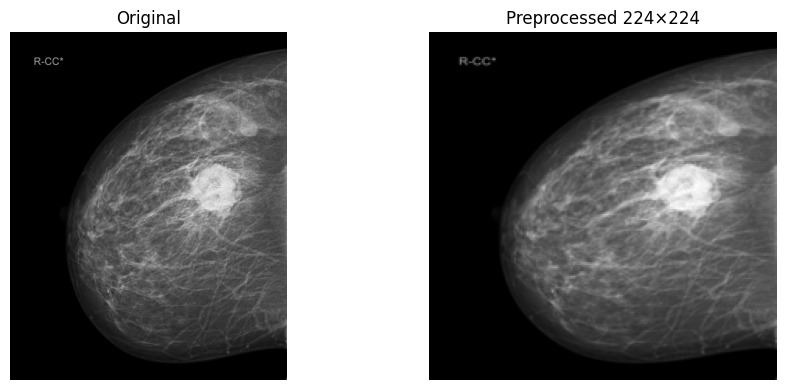


Preprocessing pipeline validated.


In [13]:
# ============================================================
# 11. IMAGE PREPROCESSING
# BCMID Multimodal Medical AI
# ============================================================

print("=" * 70)
print("11. IMAGE PREPROCESSING")
print("=" * 70)

# ============================================================
# Configuration
# ============================================================

IMAGE_SIZE = 224

# ============================================================
# Transformation pipeline
# ============================================================

preprocess_transform = transforms.Compose([

    # Convert medical image to grayscale
    transforms.Grayscale(
        num_output_channels=1
    ),

    # Standard spatial resolution
    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    # Convert PIL image → PyTorch tensor
    transforms.ToTensor(),

    # Normalize pixel values
    transforms.Normalize(
        mean=[0.5],
        std=[0.5]
    )
])

print("Preprocessing pipeline:")
print(preprocess_transform)

# ============================================================
# Select one valid image for testing
# ============================================================

valid_image_rows = integrity_df[
    integrity_df["readable"]
]

if len(valid_image_rows) == 0:

    raise RuntimeError(
        "No readable image available for preprocessing test."
    )

sample_image_path = (
    valid_image_rows.iloc[0]["image_path"]
)

# ============================================================
# Apply preprocessing
# ============================================================

original_image = Image.open(
    sample_image_path
)

processed_tensor = preprocess_transform(
    original_image
)

# ============================================================
# Display technical information
# ============================================================

print("\nSample image:")
print(sample_image_path)

print("\nOriginal:")
print(
    "Size :",
    original_image.size
)

print(
    "Mode :",
    original_image.mode
)

print("\nProcessed:")
print(
    "Tensor shape :",
    processed_tensor.shape
)

print(
    "Tensor dtype :",
    processed_tensor.dtype
)

print(
    "Min value    :",
    processed_tensor.min().item()
)

print(
    "Max value    :",
    processed_tensor.max().item()
)

# ============================================================
# Visual comparison
# ============================================================

processed_display = (
    processed_tensor.squeeze(0)
    .numpy()
)

processed_display = (
    processed_display + 1
) / 2

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(
    original_image,
    cmap="gray"
)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(
    processed_display,
    cmap="gray"
)
plt.title("Preprocessed 224×224")
plt.axis("off")

plt.tight_layout()
plt.show()

print("\nPreprocessing pipeline validated.")

In [14]:
# ============================================================
# 12. PATIENT-LEVEL DATASET SPLIT
# BCMID Multimodal Medical AI
# ============================================================

print("=" * 70)
print("12. PATIENT-LEVEL DATASET SPLIT")
print("=" * 70)

# ============================================================
# 1. Keep only validated multimodal patients
# ============================================================

valid_patients = validation_df[
    validation_df["is_valid"]
].copy()

print(
    "Validated patients:",
    len(valid_patients)
)

if len(valid_patients) == 0:
    raise RuntimeError(
        "No validated patients available for splitting."
    )

# ============================================================
# 2. Check BI-RADS classes
# ============================================================

class_counts = (
    valid_patients["birads"]
    .value_counts()
)

print("\nBI-RADS distribution:")
display(
    class_counts.to_frame("patients")
)

# ============================================================
# 3. Determine whether stratification is possible
# ============================================================

can_stratify = (
    class_counts.min() >= 2
)

stratify_target = (
    valid_patients["birads"]
    if can_stratify
    else None
)

if can_stratify:

    print(
        "\nStratified patient-level split enabled."
    )

else:

    print(
        "\nWarning: some BI-RADS classes have "
        "fewer than 2 patients."
    )

    print(
        "Non-stratified split will be used."
    )

# ============================================================
# 4. Train = 70%
# Remaining = 30%
# ============================================================

train_df, temp_df = train_test_split(

    valid_patients,

    test_size=0.30,

    random_state=SEED,

    stratify=stratify_target
)

# ============================================================
# 5. Validation = 15%
# Test = 15%
# ============================================================

if can_stratify:

    temp_class_counts = (
        temp_df["birads"]
        .value_counts()
    )

    can_stratify_temp = (
        temp_class_counts.min() >= 2
    )

else:

    can_stratify_temp = False

temp_stratify = (
    temp_df["birads"]
    if can_stratify_temp
    else None
)

val_df, test_df = train_test_split(

    temp_df,

    test_size=0.50,

    random_state=SEED,

    stratify=temp_stratify
)

# ============================================================
# 6. Add split labels
# ============================================================

train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

train_df["split"] = "train"
val_df["split"] = "validation"
test_df["split"] = "test"

# ============================================================
# 7. Verify patient leakage
# ============================================================

train_ids = set(
    train_df["patient_id"]
)

val_ids = set(
    val_df["patient_id"]
)

test_ids = set(
    test_df["patient_id"]
)

train_val_overlap = (
    train_ids & val_ids
)

train_test_overlap = (
    train_ids & test_ids
)

val_test_overlap = (
    val_ids & test_ids
)

# ============================================================
# 8. Display results
# ============================================================

print("\nDataset split:")
print(
    f"Train      : {len(train_df)} patients"
)

print(
    f"Validation : {len(val_df)} patients"
)

print(
    f"Test       : {len(test_df)} patients"
)

print("\nPatient leakage check:")

print(
    "Train ∩ Validation :",
    len(train_val_overlap)
)

print(
    "Train ∩ Test       :",
    len(train_test_overlap)
)

print(
    "Validation ∩ Test  :",
    len(val_test_overlap)
)

if (
    len(train_val_overlap)
    == 0
    and
    len(train_test_overlap)
    == 0
    and
    len(val_test_overlap)
    == 0
):

    print(
        "\n✓ No patient leakage detected."
    )

else:

    raise RuntimeError(
        "Patient leakage detected!"
    )

# ============================================================
# 9. BI-RADS distribution by split
# ============================================================

print("\nTrain BI-RADS distribution:")
display(
    train_df["birads"]
    .value_counts()
    .to_frame("patients")
)

print("\nValidation BI-RADS distribution:")
display(
    val_df["birads"]
    .value_counts()
    .to_frame("patients")
)

print("\nTest BI-RADS distribution:")
display(
    test_df["birads"]
    .value_counts()
    .to_frame("patients")
)

12. PATIENT-LEVEL DATASET SPLIT
Validated patients: 331

BI-RADS distribution:


,patients
birads,
2,166
1,50
3,47
4,24
6,24
5,15
0,5



Stratified patient-level split enabled.

Dataset split:
Train      : 231 patients
Validation : 50 patients
Test       : 50 patients

Patient leakage check:
Train ∩ Validation : 0
Train ∩ Test       : 0
Validation ∩ Test  : 0

✓ No patient leakage detected.

Train BI-RADS distribution:


,patients
birads,
2,116
1,35
3,33
6,17
4,17
5,10
0,3



Validation BI-RADS distribution:


,patients
birads,
2,25
1,7
3,7
6,4
4,4
5,2
0,1



Test BI-RADS distribution:


,patients
birads,
2,25
1,8
3,7
5,3
6,3
4,3
0,1


In [15]:
# ============================================================
# 13. QUALITY REPORT
# BCMID Multimodal Medical AI
# ============================================================

print("=" * 70)
print("13. QUALITY REPORT")
print("=" * 70)

# ============================================================
# Patient statistics
# ============================================================

total_patients = len(manifest)

patients_with_mammogram = int(
    manifest["has_mammogram"].sum()
)

patients_with_ultrasound = int(
    manifest["has_ultrasound"].sum()
)

patients_with_both = int(
    (
        manifest["has_mammogram"]
        &
        manifest["has_ultrasound"]
    ).sum()
)

patients_with_birads = int(
    manifest["birads"].notna().sum()
)

valid_patients_count = int(
    validation_df["is_valid"].sum()
)

# ============================================================
# Image statistics
# ============================================================

total_images = len(
    integrity_df
)

readable_images = int(
    integrity_df["readable"].sum()
)

unreadable_images = (
    total_images
    -
    readable_images
)

duplicate_records = len(
    duplicates_df
)

suspicious_records = len(
    suspicious_images
)

# ============================================================
# BI-RADS distribution
# ============================================================

birads_distribution = (
    manifest["birads"]
    .value_counts(
        dropna=False
    )
    .to_dict()
)

# Convert keys to strings
birads_distribution = {
    str(key): int(value)
    for key, value
    in birads_distribution.items()
}

# ============================================================
# Complete report
# ============================================================

quality_report = {

    "project": {
        "name":
            "BCMID Multimodal Medical AI",

        "dataset":
            "BCMID",

        "version":
            "v3",

        "purpose":
            "Multimodal BI-RADS classification"
    },

    "patients": {

        "total":
            total_patients,

        "with_mammogram":
            patients_with_mammogram,

        "with_ultrasound":
            patients_with_ultrasound,

        "with_both_modalities":
            patients_with_both,

        "with_birads_annotation":
            patients_with_birads,

        "validated":
            valid_patients_count
    },

    "images": {

        "total":
            total_images,

        "readable":
            readable_images,

        "unreadable":
            unreadable_images,

        "duplicates":
            duplicate_records,

        "suspicious":
            suspicious_records
    },

    "bi_rads_distribution":
        birads_distribution,

    "dataset_split": {

        "train":
            len(train_df),

        "validation":
            len(val_df),

        "test":
            len(test_df)
    },

    "validation": {

        "patient_level_split":
            True,

        "data_leakage_detected":
            False
    }
}

# ============================================================
# Save report
# ============================================================

QUALITY_REPORT_PATH = (
    KAGGLE_WORKING
    /
    "quality_report.json"
)

with open(
    QUALITY_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        quality_report,
        file,
        indent=4,
        ensure_ascii=False
    )

# ============================================================
# Display report
# ============================================================

print("\nQuality report generated:")
print(QUALITY_REPORT_PATH)

print("\n" + "-" * 70)
print("DATASET QUALITY SUMMARY")
print("-" * 70)

print(
    f"Total patients       : {total_patients}"
)

print(
    f"Both modalities      : {patients_with_both}"
)

print(
    f"Total images         : {total_images}"
)

print(
    f"Readable images      : {readable_images}"
)

print(
    f"Unreadable images    : {unreadable_images}"
)

print(
    f"Duplicate records    : {duplicate_records}"
)

print(
    f"Validated patients   : {valid_patients_count}"
)

print(
    f"Train patients       : {len(train_df)}"
)

print(
    f"Validation patients  : {len(val_df)}"
)

print(
    f"Test patients        : {len(test_df)}"
)

print("\nQuality report completed.")

13. QUALITY REPORT

Quality report generated:
/kaggle/working/quality_report.json

----------------------------------------------------------------------
DATASET QUALITY SUMMARY
----------------------------------------------------------------------
Total patients       : 332
Both modalities      : 332
Total images         : 2001
Readable images      : 2000
Unreadable images    : 1
Duplicate records    : 13
Validated patients   : 331
Train patients       : 231
Validation patients  : 50
Test patients        : 50

Quality report completed.


In [16]:
# ============================================================
# 14. SAVE VALIDATED DATASET
# BCMID Multimodal Medical AI
# ============================================================

print("=" * 70)
print("14. SAVE VALIDATED DATASET")
print("=" * 70)

# ============================================================
# Create output directory
# ============================================================

VALIDATED_DIR = (
    KAGGLE_WORKING
    /
    "BCMID_validated"
)

VALIDATED_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ============================================================
# 1. Save complete validation manifest
# ============================================================

validation_df.to_csv(

    VALIDATED_DIR
    /
    "bcmid_validated_manifest.csv",

    index=False
)

# ============================================================
# 2. Save train manifest
# ============================================================

train_df.to_csv(

    VALIDATED_DIR
    /
    "train_manifest.csv",

    index=False
)

# ============================================================
# 3. Save validation manifest
# ============================================================

val_df.to_csv(

    VALIDATED_DIR
    /
    "validation_manifest.csv",

    index=False
)

# ============================================================
# 4. Save test manifest
# ============================================================

test_df.to_csv(

    VALIDATED_DIR
    /
    "test_manifest.csv",

    index=False
)

# ============================================================
# 5. Save clean annotations
# ============================================================

annotations.to_csv(

    VALIDATED_DIR
    /
    "annotations_clean.csv",

    index=False
)

# ============================================================
# 6. Save image integrity information
# ============================================================

integrity_df.to_csv(

    VALIDATED_DIR
    /
    "image_integrity.csv",

    index=False
)

# ============================================================
# 7. Save image quality information
# ============================================================

quality_df.to_csv(

    VALIDATED_DIR
    /
    "image_quality.csv",

    index=False
)

# ============================================================
# 8. Save duplicates
# ============================================================

duplicates_df.to_csv(

    VALIDATED_DIR
    /
    "duplicates.csv",

    index=False
)

# ============================================================
# 9. Save suspicious images
# ============================================================

suspicious_images.to_csv(

    VALIDATED_DIR
    /
    "suspicious_images.csv",

    index=False
)

# ============================================================
# 10. Save quality report
# ============================================================

with open(
    QUALITY_REPORT_PATH,
    "r",
    encoding="utf-8"
) as source:

    quality_report_content = (
        source.read()
    )

with open(
    VALIDATED_DIR
    /
    "quality_report.json",
    "w",
    encoding="utf-8"
) as destination:

    destination.write(
        quality_report_content
    )

# ============================================================
# 11. Save configuration
# ============================================================

with open(
    VALIDATED_DIR
    /
    "preprocessing_config.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        {
            "image_size": IMAGE_SIZE,
            "grayscale": True,
            "normalization_mean": [0.5],
            "normalization_std": [0.5],
            "split_strategy": "patient_level",
            "random_seed": SEED
        },
        file,
        indent=4
    )

# ============================================================
# 12. Display generated files
# ============================================================

print("\nValidated dataset directory:")
print(VALIDATED_DIR)

print("\nGenerated files:")
print("-" * 70)

for file in sorted(
    VALIDATED_DIR.iterdir()
):

    size_kb = (
        file.stat().st_size
        / 1024
    )

    print(
        f"{file.name:<40} "
        f"{size_kb:>10.1f} KB"
    )

# ============================================================
# FINAL STATUS
# ============================================================

print("\n" + "=" * 70)
print("DATA & QUALITY AGENT - COMPLETED")
print("=" * 70)

print("""
✓ Dataset explored
✓ BI-RADS annotations loaded
✓ Patient structure analyzed
✓ Multimodal manifest created
✓ Image integrity checked
✓ Missing modalities analyzed
✓ Duplicate detection performed
✓ Image quality analyzed
✓ Data validated
✓ Preprocessing pipeline defined
✓ Patient-level split created
✓ Quality report generated
✓ Validated manifests saved

READY FOR:
→ MULTIMODAL VISION AGENT
""")

14. SAVE VALIDATED DATASET

Validated dataset directory:
/kaggle/working/BCMID_validated

Generated files:
----------------------------------------------------------------------
annotations_clean.csv                           3.4 KB
bcmid_validated_manifest.csv                  280.7 KB
duplicates.csv                                  2.7 KB
image_integrity.csv                           294.4 KB
image_quality.csv                             431.2 KB
preprocessing_config.json                       0.2 KB
quality_report.json                             0.9 KB
suspicious_images.csv                           0.1 KB
test_manifest.csv                              48.2 KB
train_manifest.csv                            193.5 KB
validation_manifest.csv                        40.5 KB

DATA & QUALITY AGENT - COMPLETED

✓ Dataset explored
✓ BI-RADS annotations loaded
✓ Patient structure analyzed
✓ Multimodal manifest created
✓ Image integrity checked
✓ Missing modalities analyzed
✓ Duplicate detecti